# セグメンテーション (金額の区切り方の比較)

## 目的

[ADR 011](../docs/decisions/011_segmentation_purpose_and_roles.md) に従い、顧客をルールでセグメントに分ける。

- リピーター (`order_count >= 2`) は 1 つのセグメントにする
- 単発購入の顧客 (`order_count = 1`) は、`total_items_amount` で区切る

この notebook では、単発購入の顧客の金額の区切り方の候補 (中央値、三分位、四分位、K-means の境界、切りのよい値) を比べ、区切り方を決める。
K-means の境界は、自然な境目とは限らないため、候補の 1 つとして扱う。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from sklearn.cluster import KMeans

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する
features = client.query("select * from olist_mart.customer_features").to_dataframe()

# NUMERIC は Decimal、真偽値は boolean として読まれるため float にする
NUMERIC_COLUMNS = [
    "total_items_amount",
    "order_count",
    "item_count",
    "credit_card_order_ratio",
    "avg_review_score",
    "has_review_comment",
    "avg_delivery_days",
    "late_delivery_ratio",
]
customers = features[["customer_unique_id"]].join(features[NUMERIC_COLUMNS].astype("float"))

single = customers[customers["order_count"] == 1]
amount = single["total_items_amount"]
print(f"全顧客: {len(customers):,} 人 / リピーター: {(customers['order_count'] >= 2).sum():,} 人 / 単発購入: {len(single):,} 人")

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


全顧客: 93,358 人 / リピーター: 2,801 人 / 単発購入: 90,557 人


## 1. 単発購入の顧客の金額の分布と、区切り方の候補

金額の単位は、データの通貨 (ブラジルレアル)。

In [2]:
amount.quantile([0.1, 0.25, 1 / 3, 0.5, 2 / 3, 0.75, 0.9]).round(2).to_frame("total_items_amount")

,total_items_amount
0.100000,25.24
0.250000,45.90
0.333333,56.99
0.500000,86.96
0.666667,122.99
0.750000,149.90
0.900000,269.90


In [3]:
# K-means の境界: 対数を取った金額だけで K-means を行い、隣り合う中心の中点を元の金額に戻す
log_amount = np.log1p(amount).to_numpy().reshape(-1, 1)
kmeans_bounds = {}
for k in (2, 3):
    centers = np.sort(KMeans(n_clusters=k, n_init=20, random_state=0).fit(log_amount).cluster_centers_.ravel())
    kmeans_bounds[k] = np.expm1((centers[:-1] + centers[1:]) / 2).round(1).tolist()
kmeans_bounds

{2: [84.0], 3: [56.2, 184.0]}

候補の境界。区間は「下限を含み、上限を含まない」(例: 50 ちょうどは 50 以上の区分に入る)。

In [4]:
CANDIDATES = {
    "median (2)": [amount.median()],
    "kmeans (2)": kmeans_bounds[2],
    "tertile (3)": [amount.quantile(1 / 3), amount.quantile(2 / 3)],
    "kmeans (3)": kmeans_bounds[3],
    "round 50/150 (3)": [50, 150],
    "quartile (4)": [amount.quantile(0.25), amount.quantile(0.5), amount.quantile(0.75)],
    "round 50/100/200 (4)": [50, 100, 200],
}
pd.Series({name: [round(b, 2) for b in bounds] for name, bounds in CANDIDATES.items()}).to_frame("bounds")

,bounds
median (2),[86.96]
kmeans (2),[84.0]
tertile (3),"[56.99, 122.99]"
kmeans (3),"[56.2, 184.0]"
round 50/150 (3),"[50, 150]"
quartile (4),"[45.9, 86.96, 149.9]"
round 50/100/200 (4),"[50, 100, 200]"


## 2. 候補ごとの顧客像

区分ごとに、人数と、購入体験・解釈用の指標を見る。平均や割合は、NULL の顧客を分母に入れずに計算する (ADR 011)。

- `late_rate`: 遅延を経験した顧客の割合
- `review_mean`: レビューの評価の平均
- `low_review_rate`: レビューの評価が 3 以下の顧客の割合
- `no_review_rate`: レビューがない顧客の割合
- `comment_rate`: コメントがある顧客の割合
- `multi_item_rate`: 複数の商品を買った顧客の割合
- `card_rate`: クレジットカードを使った顧客の割合

In [5]:
def summarize(data: pd.DataFrame, groups: pd.Series) -> pd.DataFrame:
    """グループごとの人数と、購入体験・解釈用の指標を返す (NULL は分母に入れない)。"""
    grouped = data.groupby(groups, observed=True)
    review = data["avg_review_score"]
    return pd.DataFrame({
        "n": grouped.size(),
        "amount_median": grouped["total_items_amount"].median(),
        "late_rate": grouped["late_delivery_ratio"].apply(lambda s: (s.dropna() > 0).mean()),
        "delivery_days_mean": grouped["avg_delivery_days"].mean(),
        "review_mean": grouped["avg_review_score"].mean(),
        "low_review_rate": (review <= 3).astype("float").where(review.notna()).groupby(groups, observed=True).mean(),
        "no_review_rate": review.isna().groupby(groups, observed=True).mean(),
        "comment_rate": grouped["has_review_comment"].mean(),
        "multi_item_rate": (data["item_count"] >= 2).groupby(groups, observed=True).mean(),
        "card_rate": grouped["credit_card_order_ratio"].mean(),
    }).round(3)


def cut_amount(bounds: list[float]) -> pd.Series:
    """単発購入の顧客の金額を、境界で区切った区分を返す (下限を含み、上限を含まない)。"""
    edges = [-np.inf, *bounds, np.inf]
    return pd.cut(amount, bins=edges, right=False, labels=[f"tier{i + 1}" for i in range(len(bounds) + 1)])


for name, bounds in CANDIDATES.items():
    print(name)
    display(summarize(single, cut_amount(bounds)))

median (2)


,n,amount_median,late_rate,delivery_days_mean,review_mean,low_review_rate,no_review_rate,comment_rate,multi_item_rate,card_rate
total_items_amount,,,,,,,,,,
tier1,45278,45.9,0.064,11.812,4.193,0.201,0.006,0.406,0.055,0.738
tier2,45279,149.9,0.073,13.217,4.110,0.222,0.007,0.442,0.139,0.802


kmeans (2)


,n,amount_median,late_rate,delivery_days_mean,review_mean,low_review_rate,no_review_rate,comment_rate,multi_item_rate,card_rate
total_items_amount,,,,,,,,,,
tier1,44133,45.0,0.064,11.778,4.196,0.200,0.006,0.405,0.055,0.737
tier2,46424,149.9,0.073,13.215,4.110,0.222,0.007,0.442,0.137,0.801


tertile (3)


...

,n,amount_median,late_rate,delivery_days_mean,review_mean,low_review_rate,no_review_rate,comment_rate,multi_item_rate,card_rate
total_items_amount,,,,,,,,,,
tier1,26929,29.99,0.061,11.502,4.213,0.198,0.006,0.394,0.039,0.720
tier2,41399,89.99,0.069,12.562,4.160,0.208,0.006,0.428,0.093,0.776
tier3,22229,235.40,0.077,13.652,4.063,0.235,0.008,0.452,0.175,0.819


quartile (4)


,n,amount_median,late_rate,delivery_days_mean,review_mean,low_review_rate,no_review_rate,comment_rate,multi_item_rate,card_rate
total_items_amount,,,,,,,,,,
tier1,22357,29.00,0.060,11.380,4.216,0.197,0.006,0.392,0.039,0.715
tier2,22921,59.99,0.068,12.234,4.172,0.205,0.006,0.419,0.072,0.761
tier3,22059,110.80,0.069,12.756,4.155,0.210,0.006,0.433,0.109,0.786
tier4,23220,229.90,0.077,13.654,4.068,0.233,0.008,0.451,0.168,0.817


round 50/100/200 (4)


,n,amount_median,late_rate,delivery_days_mean,review_mean,low_review_rate,no_review_rate,comment_rate,multi_item_rate,card_rate
total_items_amount,,,,,,,,,,
tier1,26929,29.99,0.061,11.502,4.213,0.198,0.006,0.394,0.039,0.720
tier2,25960,74.90,0.067,12.321,4.164,0.207,0.006,0.424,0.082,0.767
tier3,23834,139.90,0.072,13.144,4.137,0.214,0.007,0.434,0.124,0.797
tier4,13834,319.99,0.080,13.762,4.036,0.243,0.008,0.464,0.193,0.826


### 金額と指標の関係

区切り方によらない傾向を見るため、金額を 20 等分 (各区分の人数がほぼ同じ) して、指標の変化を見る。
縦の点線は、切りのよい値の候補 (50 と 150)。

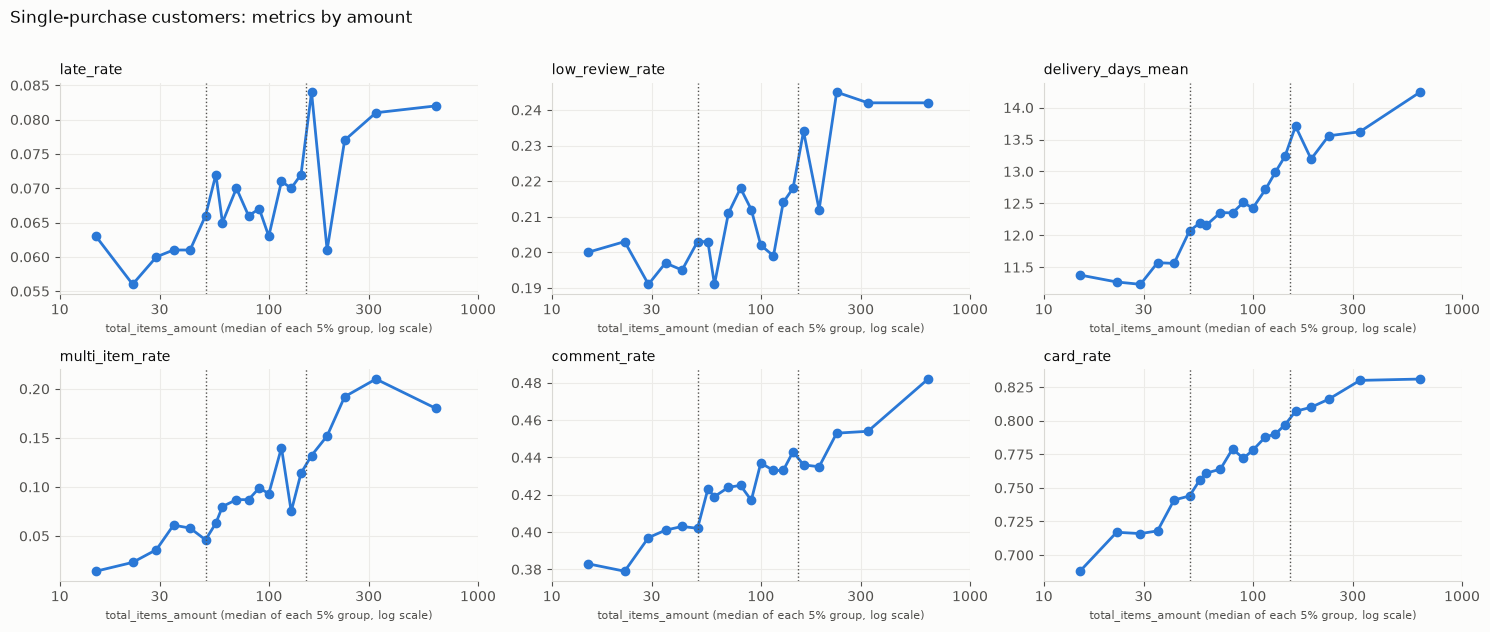

In [6]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SERIES = "#2a78d6"  # 各グラフは単一系列のため 1 色のみ

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

ventiles = pd.qcut(amount, q=20)
by_ventile = summarize(single, ventiles)
x = single.groupby(ventiles, observed=True)["total_items_amount"].median()

METRICS = ["late_rate", "low_review_rate", "delivery_days_mean", "multi_item_rate", "comment_rate", "card_rate"]
AMOUNT_TICKS = [10, 30, 100, 300, 1000]

fig, axes = plt.subplots(2, 3, figsize=(15, 6.4))
for ax, metric in zip(axes.flat, METRICS):
    ax.plot(x, by_ventile[metric], color=SERIES, linewidth=2, marker="o", markersize=6)
    for bound in (50, 150):
        ax.axvline(bound, color=TEXT_SECONDARY, linewidth=1, linestyle=":")
    ax.set_xscale("log")
    ax.set_xticks(AMOUNT_TICKS, AMOUNT_TICKS)
    ax.minorticks_off()
    ax.set_title(metric, fontsize=10, loc="left")
    ax.set_xlabel("total_items_amount (median of each 5% group, log scale)", fontsize=8)
fig.suptitle("Single-purchase customers: metrics by amount", x=0.01, ha="left", color=TEXT_PRIMARY)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

### 比較の考察

- どの区切り方でも、金額が大きい区分ほど、どの指標も同じ向きに変わる (金額が最も小さい区分 → 最も大きい区分で、遅延率 約 6% → 約 8%、低評価率 約 20% → 約 24%、配送日数 約 11.5 日 → 約 13.7 日、複数商品の割合 約 4% → 約 18%)。
- 20 等分のグラフでは、配送日数・カード・コメントはなめらかに増える。遅延率と低評価率は、全体としては増えるが、隣り合う区分どうしで上下するばらつきがあり、差も小さい (縦軸は 0 から始めていないため、差が大きく見えることに注意)。
- 特定の金額を境に、はっきり変わる段差は見られない。区切り方を変えても、見える傾向はほとんど変わらない。
- 差は小さめで、金額の大きい区分ほど複数商品の割合も高い。配送日数や遅延の違いは、金額そのものではなく、商品の数や大きさなどの影響である可能性がある (セグメント別の分析で確認する)。

## 3. 区切り方の決定

自然な境目がないため、**説明しやすさで選び、切りのよい値 (50 と 150) で 3 つに区切る**。

- 150 は 75% 点 (149.9) とほぼ同じで、「単発購入の顧客の上位 約 25%」とも説明できる。50 は、およそ 30% 点。
- K-means の境界 (2 区分で 84、3 区分で 56 と 184) は、切りのよい値でなく、自然な境目である根拠もない。
- 三分位は人数がそろうが、境界 (57 と 123) が説明しにくい。
- 区分が 2 つだと金額による違いを見る段階が少なく、4 つだと各区分の差がさらに小さくなる。

## 4. セグメントの割り当て

In [7]:
SEGMENT_ORDER = ["repeat", "single_high", "single_mid", "single_low"]


def assign_segment(data: pd.DataFrame) -> pd.Series:
    """ADR 012 のルールで、顧客をセグメントに割り当てる。"""
    conditions = [
        data["order_count"] >= 2,
        data["total_items_amount"] >= 150,
        data["total_items_amount"] >= 50,
    ]
    segment = np.select(conditions, SEGMENT_ORDER[:3], default="single_low")
    return pd.Series(pd.Categorical(segment, categories=SEGMENT_ORDER, ordered=True), index=data.index, name="segment")


segment = assign_segment(customers)
summarize(customers, segment)

,n,amount_median,late_rate,delivery_days_mean,review_mean,low_review_rate,no_review_rate,comment_rate,multi_item_rate,card_rate
segment,,,,,,,,,,
repeat,2801,182.10,0.108,12.262,4.203,0.193,0.003,0.528,1.000,0.774
single_high,22229,235.40,0.077,13.652,4.063,0.235,0.008,0.452,0.175,0.819
single_mid,41399,89.99,0.069,12.562,4.160,0.208,0.006,0.428,0.093,0.776
single_low,26929,29.99,0.061,11.502,4.213,0.198,0.006,0.394,0.039,0.720


In [8]:
# 全顧客が、ちょうど 1 つのセグメントに入ることを確かめる
assert segment.notna().all()
assert len(segment) == len(customers) == 93_358
segment.value_counts().reindex(SEGMENT_ORDER).to_frame("customers").assign(share=lambda df: (df["customers"] / len(customers)).round(3))

,customers,share
segment,,
repeat,2801,0.030
single_high,22229,0.238
single_mid,41399,0.443
single_low,26929,0.288


- 各セグメントの購入体験の比較 (購入時期をそろえた確認を含む) は、次の notebook で行う。
- リピーターは、顧客単位で見ると注文の数が多い。そのため「遅延を経験した顧客の割合」は単発購入の顧客より高くなりやすく、複数商品の割合は定義上 100% になる。比べるときは、注文単位の指標もあわせて見る。